In [3]:
pip install kagglehub



   ---------------------------------------- 0/5 [tqdm]
   ---------------------------------------- 0/5 [tqdm]
   ---------------------------------------- 0/5 [tqdm]
   -------- ------------------------------- 1/5 [pyyaml]
   ---------------- ----------------------- 2/5 [protobuf]
   ---------------- ----------------------- 2/5 [protobuf]
   ---------------- ----------------------- 2/5 [protobuf]
   ---------------- ----------------------- 2/5 [protobuf]
   ---------------- ----------------------- 2/5 [protobuf]
   ---------------- ----------------------- 2/5 [protobuf]
   ------------------------ --------------- 3/5 [kagglesdk]
   ------------------------ --------------- 3/5 [kagglesdk]
   ------------------------ --------------- 3/5 [kagglesdk]
   ------------------------ --------------- 3/5 [kagglesdk]
   ------------------------ --------------- 3/5 [kagglesdk]
   ------------------------ --------------- 3/5 [kagglesdk]
   ------------------------ --------------- 3/5 [kagglesdk]
   

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.3 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")

print("Path to dataset files:", path)

c:\Users\llam_\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 117M/117M [00:06<00:00, 19.5MB/s] 

Extracting files...


Path to dataset files: C:\Users\llam_\.cache\kagglehub\datasets\asaniczka\uk-optimal-product-price-prediction\versions\3


In [5]:
import pandas as pd
import os

path = r"C:\Users\llam_\.cache\kagglehub\datasets\asaniczka\uk-optimal-product-price-prediction\versions\3"

files = [f for f in os.listdir(path) if f.endswith('.csv')]
file_path = os.path.join(path, files[0])

df = pd.read_csv(file_path)

In [6]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [14]:
print(df.columns)

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='str')


In [8]:
category_counts = df["category"].value_counts()
category_counts

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [10]:
top_5category = category_counts.head(5)
print(top_5category)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

C:\Users\llam_\AppData\Local\Temp\ipykernel_100588\4080979494.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=category_counts.head(20).values, y=category_counts.head(20).index, palette="viridis")


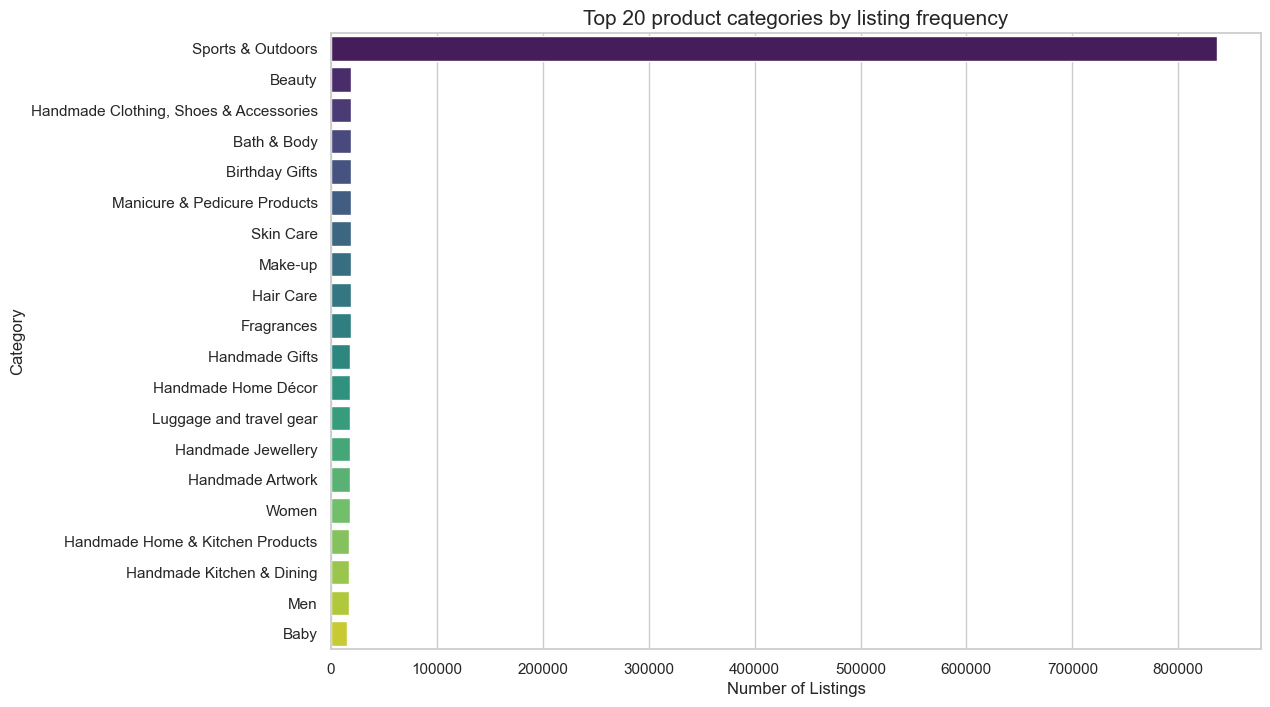

In [17]:
plt.figure(figsize=(12, 8))

sns.barplot(x=category_counts.head(20).values, y=category_counts.head(20).index, palette="viridis")
plt.title("Top 20 product categories by listing frequency", fontsize=15)
plt.xlabel("Number of Listings")
plt.ylabel("Category")
plt.show()

In [ ]:
#haré el plot con un top 10 para que no quede muy lleno de información

In [18]:
top_10plot = category_counts.head(10)

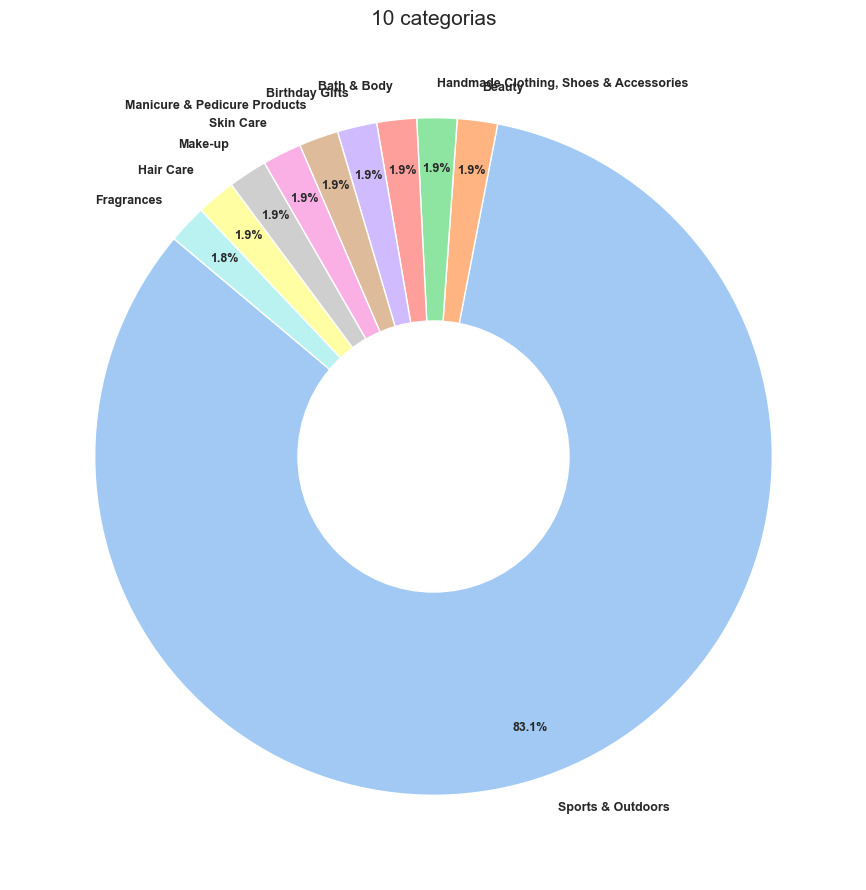

In [30]:
plt.figure(figsize=(15,11))

propiedades_texto = {'fontsize': 9, 'fontweight': 'bold'}

plt.pie(top_10plot,
         labels=top_10plot.index,
         autopct='%1.1f%%',
         startangle=140,
         colors=sns.color_palette("pastel"),
         pctdistance=0.85,
         textprops=propiedades_texto)
centro_circulo = plt.Circle((0,0), 0.40, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centro_circulo)

        

plt.title("10 categorias", fontsize=15)
plt.show()

In [31]:
list(set(df.dtypes.tolist()))

[<StringDtype(storage='python', na_value=nan)>,
 dtype('float64'),
 dtype('bool'),
 dtype('int64')]

In [32]:
df.select_dtypes("number").columns

Index(['uid', 'stars', 'reviews', 'price', 'boughtInLastMonth'], dtype='str')

In [33]:
df.select_dtypes("number").nunique().sort_values(ascending=False)

uid                  2443651
price                  82916
reviews                19446
stars                     42
boughtInLastMonth         25
dtype: int64

In [34]:
df.isnull().sum().sort_values(ascending=False)

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [40]:
def analyze_stats(data_frame, colum_name):
    mean_val = data_frame[colum_name].mean()
    median_val = data_frame[colum_name].median()
    mode_series = data_frame[colum_name].mode()
    mode_val = mode_series[0] if not mode_series.empty else 0
    print(f"--- Stats Analysis: {colum_name} ---")
    print(f"Mean:  {mean_val:,.2f}")
    print(f"Median:  {median_val:,.2f}")
    print(f"Mode:     {mode_val:,.2f}")

    return {"mean": mean_val, "median": median_val, "mode": mode_val}

stats_preu = analyze_stats(df, 'price')

--- Stats Analysis: price ---
Mean:  89.24
Median:  19.09
Mode:     9.99


In [ ]:
# El precio medio (AVG) es de 89.24, y el modal 9.99, podemos ver una gran diferencia, lo más probable es que la media se vea desplazada por productos muy caros, seguramente de lujo o simplemente algún tipo de producto con precios más elevades, ccomo electrodomesticos. Aun asi, el precio que más se repite, és de 9.99, por lo  tanto, podemos concluir que la mayoria de clientes busca precios competitivos en la plataforma. Hay un sesgo Right Skew muy marcado.

In [42]:
def analyze_dispersion(data_frame, column_name):

    var_val = data_frame[column_name].var()
    std_val = data_frame[column_name].std()
    min_val = data_frame[column_name].min()
    max_val = data_frame[column_name].max()

    price_range = max_val - min_val
    q1 = data_frame[column_name].quantile(0.25)
    q3 = data_frame[column_name].quantile(0.75)
    iqr_val = q3 - q1

    cv_val = (std_val / data_frame[column_name].mean()) * 100

    print(f"--- Ánalisis de Dispersión: {column_name} ---")
    print(f"Variancia:            {var_val:,.2f}")
    print(f"Desviación Estándard:  {std_val:,.2f}")
    print(f"Rango (Mín-Max):       {price_range:,.2f} ({min_val} a {max_val})")
    print(f"IQR (Franja Central): {iqr_val:,.2f} (de {q1} a {q3})")
    print(f"Coef. de Variación:    {cv_val:.1f}%")
    
    return {"std": std_val, "iqr": iqr_val, "cv": cv_val}
dispersion_precios = analyze_dispersion(df, 'price')



--- Ánalisis de Dispersión: price ---
Variancia:            119,445.49
Desviación Estándard:  345.61
Rango (Mín-Max):       100,000.00 (0.0 a 100000.0)
IQR (Franja Central): 36.00 (de 9.99 a 45.99)
Coef. de Variación:    387.3%


In [ ]:
#hay una gran variación debido al precio del produicot max (100k) y min (0). Aún así, podemos ver, gracias a la franja central (IQR) que los precios reales suelen ir de 9 eu a 46 eu.

In [47]:
def plot_distribution(data_frame, column_name, max_limit=None):
    plot_data = data_frame[column_name]
    if max_limit:
        plot_data = plot_data[plot_data <= max_limit]

    fig, ax =plt.subplots(1, 2, figsize=(15,5))

    sns.histplot(plot_data, bins=30, kde=True, ax=ax[0], color='skyblue')
    ax[0].set_title(f"Histograma de {column_name}")

    sns.boxplot(x=plot_data, ax=ax[1], color='salmon')
    ax[1].set_title(f'Boxplot de {column_name}')

    plt.tight_layout()
    plt.show()

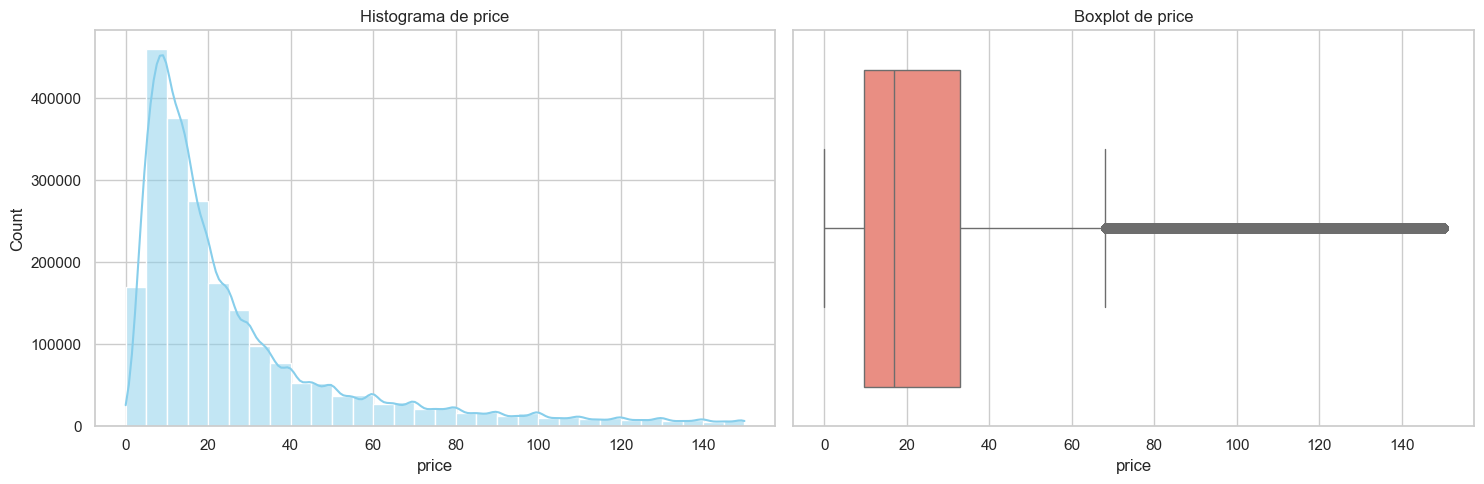

In [48]:
plot_distribution(df, 'price', max_limit=150)

In [ ]:
#Aún que hay precios más altos que los demás, que van hasta los 140 euros, la mayoria de productos se concentran en precios alrededor de 20 euros, de 10 a 35 +-

In [50]:
def analyze_stats(data_frame, colum_name):
    mean_val = data_frame[colum_name].mean()
    median_val = data_frame[colum_name].median()
    mode_series = data_frame[colum_name].mode()
    mode_val = mode_series[0] if not mode_series.empty else 0
    print(f"--- Stats Analysis: {colum_name} ---")
    print(f"Mean:  {mean_val:,.2f}")
    print(f"Median:  {median_val:,.2f}")
    print(f"Mode:     {mode_val:,.2f}")

    return {"mean": mean_val, "median": median_val, "mode": mode_val}

stats_preu = analyze_stats(df, 'stars')

--- Stats Analysis: stars ---
Mean:  2.15
Median:  0.00
Mode:     0.00


In [51]:
def analyze_dispersion(data_frame, column_name):

    var_val = data_frame[column_name].var()
    std_val = data_frame[column_name].std()
    min_val = data_frame[column_name].min()
    max_val = data_frame[column_name].max()

    price_range = max_val - min_val
    q1 = data_frame[column_name].quantile(0.25)
    q3 = data_frame[column_name].quantile(0.75)
    iqr_val = q3 - q1

    cv_val = (std_val / data_frame[column_name].mean()) * 100

    print(f"--- Ánalisis de Dispersión: {column_name} ---")
    print(f"Variancia:            {var_val:,.2f}")
    print(f"Desviación Estándard:  {std_val:,.2f}")
    print(f"Rango (Mín-Max):       {price_range:,.2f} ({min_val} a {max_val})")
    print(f"IQR (Franja Central): {iqr_val:,.2f} (de {q1} a {q3})")
    print(f"Coef. de Variación:    {cv_val:.1f}%")
    
    return {"std": std_val, "iqr": iqr_val, "cv": cv_val}
dispersion_precios = analyze_dispersion(df, 'stars')

--- Ánalisis de Dispersión: stars ---
Variancia:            4.82
Desviación Estándard:  2.19
Rango (Mín-Max):       5.00 (0.0 a 5.0)
IQR (Franja Central): 4.40 (de 0.0 a 4.4)
Coef. de Variación:    102.0%


In [54]:
def analyze_shape(data_frame, column_name):

    skew_val = data_frame[column_name].skew()
    kurt_val = data_frame[column_name].kurtosis()

    print(f"--- Análisi de Forma: {column_name} ---")
    print(f"Skewness (Asimetria): {skew_val:.2f}")
    print(f"Kurtosis (Curtosi):   {kurt_val:.2f}")

    if abs(skew_val) < 0.5:
        print("Interpretación: Distribución bastante simétrica.")
    elif skew_val < -0.5:
        print("Interpretación: Asimetrica negativa.")
    else:
        print("Interpretación: Asimetrica positiva.")
    return {"Skew": skew_val, "kurt": kurt_val}

In [55]:
shape_stars = analyze_shape(df, 'stars')

--- Análisi de Forma: stars ---
Skewness (Asimetria): 0.08
Kurtosis (Curtosi):   -1.93
Interpretación: Distribución bastante simétrica.


In [ ]:
#la distribución es bastante simétrica

In [57]:
def plot_distribution(data_frame, column_name, max_limit=None):
    plot_data = data_frame[column_name]
    if max_limit:
        plot_data = plot_data[plot_data <= max_limit]

    fig, ax =plt.subplots(1, 2, figsize=(15,5))

    sns.histplot(plot_data, bins=30, kde=True, ax=ax[0], color='skyblue')
    ax[0].set_title(f"Histograma de {column_name}")

    #sns.boxplot(x=plot_data, ax=ax[1], color='salmon')
    #ax[1].set_title(f'Boxplot de {column_name}')

    plt.tight_layout()
    plt.show()

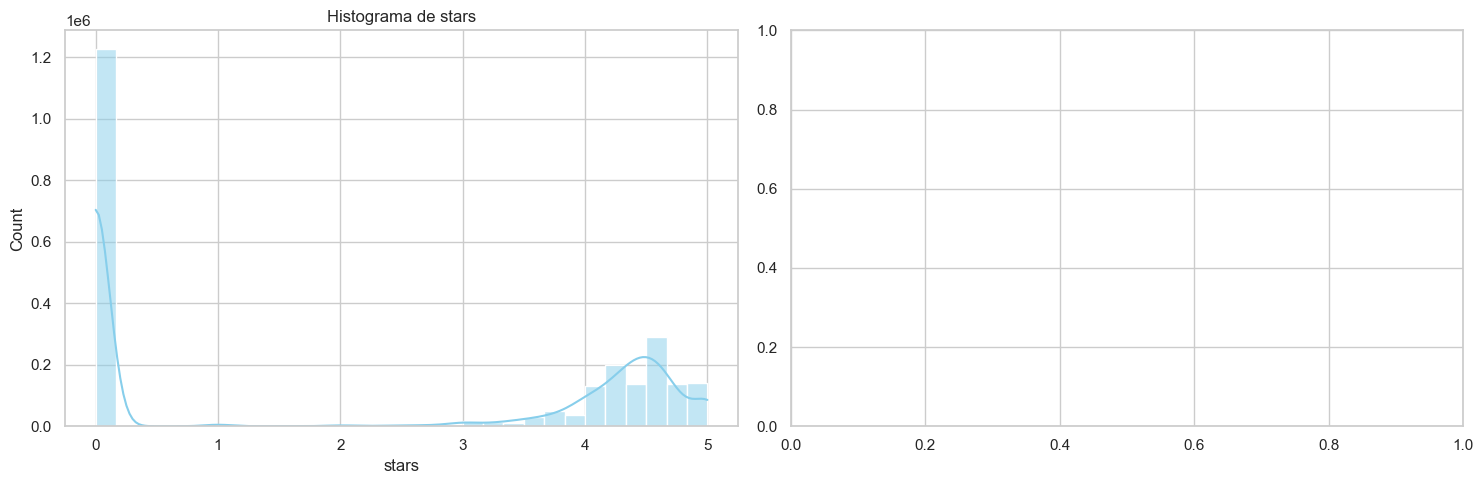

In [58]:
plot_distribution(df, 'stars', max_limit=150)

In [ ]:
#el rating más común se encuentra en 0 estrellas, y luego entre 4 y 5.

In [ ]:
"""
1. PANORAMA DE PRECIOS Y SEGMENTACIÓN
El mercado muestra una estructura de "larga cola". Aunque el rango es masivo (0£ - 100,000£), 
el núcleo del negocio (50% de los productos) se concentra entre 9.99£ y 45.99£. 
La Moda de 9.99£ confirma que el volumen masivo se mueve en precios psicológicos bajos.

2. SATISFACCIÓN DEL CLIENTE: LA POLARIZACIÓN DEL RATING
Aunque la asimetría es baja (0.08), el análisis visual revela una realidad crítica:

- EL "POZO DEL CERO": Existe una gran cantidad de productos con 0 estrellas. Esto no 
  indica insatisfacción, sino falta de tracción: productos nuevos o sin ventas que 
  inflan artificialmente la parte baja de la estadística.
- EL SEGMENTO DE ÉXITO (3.8 - 5.0): Superada la barrera del cero, la gran mayoría de 
  productos activos se concentran en valoraciones altas. Esto indica que el mercado 
  es exigente: los productos que sobreviven suelen tener buena reputación.
- EL VACÍO INTERMEDIO (1.0 - 3.0): Hay una presencia mínima de productos en este rango. 
  Conclusión: En Amazon UK, un producto o tiene éxito (3.8+) o cae en la irrelevancia (0). 
  La mediocridad no tiene volumen de mercado.

3. CONCLUSIONES ESTRATÉGICAS
- Estrategia de Precios: El éxito masivo se encuentra por debajo de las 46£. Superar 
  las 150£ requiere una estrategia de nicho/lujo fuera de la norma del catálogo.
- Calidad de Datos: Los productos con 0.0£ en precio y 0 en estrellas deben tratarse 
  como "ruido" o lanzamientos recientes para no desvirtuar el análisis de rentabilidad.
- Competitividad: Para que un producto sea visible, debe aspirar rápidamente al rango 
  de 4 estrellas, ya que el mercado ignora casi por completo las puntuaciones medias.
""""